# Sinais → métricas → IA: anomalia × inconsistência × evento esperado

**Bancada M7 (Masterclass 12/11).** Um motor, um microfone, um sensor de rotação e um de vibração. Uma pessoa aperta teclas
(`n` normal, `a` atrito, `p` palheta solta, `m` microfone tampado, `s` parada pelo app, `r` ruído da sala, `x` pós-disparo)
enquanto o registrador grava a sessão.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(".."))          # sinais/  (onde moram metricas.py e avaliar.py)
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
import inspect
from IPython.display import display, Markdown
import metricas, avaliar
JANELAS_PARA_ALERTA = 2   # espelho da constante do firmware do Mega (arduino-mega-esteira-ky.ino); so para explicar o atraso

SESSAO = '../sessoes/exemplo-simulado'
dados = avaliar.carregar(SESSAO)
linhas, av = avaliar.avaliar_sessao(dados)
manifesto = json.load(open(os.path.join(SESSAO, "manifesto.json")))
SIMULADO = manifesto.get("simulado") is True
print("sessão:", os.path.basename(os.path.normpath(SESSAO)), "| simulado:", SIMULADO, "| janelas:", len(linhas), "| épocas:", len(dados["epocas"]))
if SIMULADO:
    display(Markdown("> **Honestidade primeiro:** a sessão deste notebook é **SIMULADA** (`manifesto.json` diz `\"simulado\": true`). "
                     "Tudo o que aparece aqui é um **teste de fumaça** do pipeline: mostra que a régua funciona do jeito que desenhamos, "
                     "**não** prova que funciona num motor de verdade. A prova é a sessão gravada na bancada."))
else:
    display(Markdown("> **Sessão REAL** (`manifesto.json` diz `\"simulado\": false`): uma pessoa, um motor, uma sessão. "
                     "Os números abaixo valem para esta gravação e não são generalizáveis sem repetição."))

# números que o texto cita: todos saem de `av`, de `linhas` ou das constantes do código
F = av["faixas"]
GUARDA = inspect.signature(metricas.avaliar).parameters["guarda"].default
INI = avaliar.JANELA_CALIB
EP_BASE = next((e for e in av["epocas"] if e["baseline_ate_janela"] is not None), None)   # 1a época com baseline
FIM = EP_BASE["baseline_ate_janela"] if EP_BASE else None
NBASE = EP_BASE["baseline_n"] if EP_BASE else 0
SEM_BASE = [e["epoca"] for e in av["epocas"] if e["baseline_insuficiente"]]
SEG_S = next((c for c in av["segmentos_contexto"] if c["rotulo"] == "s"), None)
SEG_R = next((c for c in av["segmentos_contexto"] if c["rotulo"] == "r"), None)
EVENTOS_IA = "%d/%d" % (F["ia"]["episodios_detectados"], F["ia"]["episodios_total"])
N_NR_OUTRAS = sum(l["rotulo"] in ("n", "r") for l in linhas)
N_NR_IA = sum(l["rotulo"] in ("n", "r") and l["ia"] is not None and l["ia"]["avaliada"] for l in linhas)
N_POS = sum(l["pos_disparo"] for l in linhas)
def fmt(v, un=""):
    return "-" if v is None else "%.1f%s" % (v, un)

sessão: exemplo-simulado | simulado: True | janelas: 660 | épocas: 11


> **Honestidade primeiro:** a sessão deste notebook é **SIMULADA** (`manifesto.json` diz `"simulado": true`). Tudo o que aparece aqui é um **teste de fumaça** do pipeline: mostra que a régua funciona do jeito que desenhamos, **não** prova que funciona num motor de verdade. A prova é a sessão gravada na bancada.

## 1 · O que foi medido

A cada **1 s** (uma janela) o Arduino Mega manda quatro números: `rpm`, `som_rms`, `som_pico` e `vib`, mais o `score` e o `estado` do detector que roda dentro dele. O registrador grava tudo em `sinais.csv`, as teclas em `rotulos.csv`, e numera **épocas** (um bloco novo cada vez que a janela do Mega volta ao começo, ou a porta reabre).

## 2 · Os canais, com as faixas de rótulo

Cada **faixa de cor** é o que a pessoa marcou. Repare que a tecla vale **depois** da janela em que foi apertada, e que cada época começa sem rótulo até a primeira tecla. Mostramos até as 3 primeiras épocas da sessão.

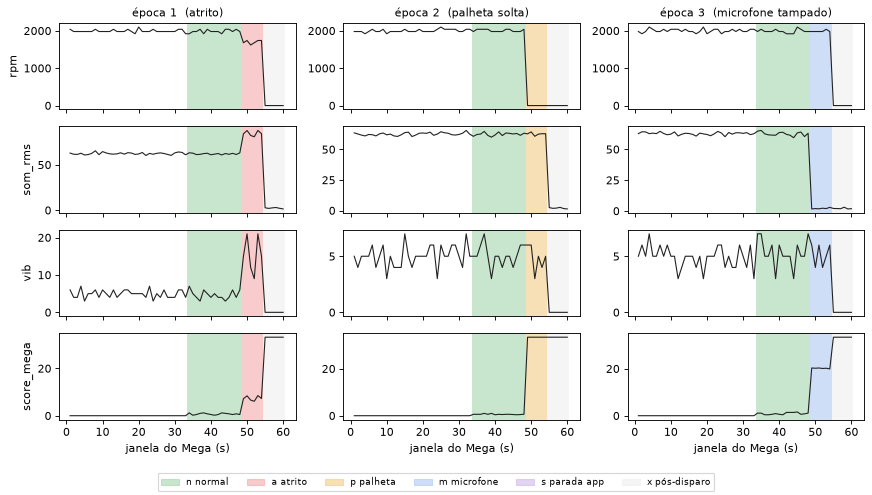

In [2]:
CORES = {"n": "#9bd3a6", "a": "#f4a3a3", "p": "#f2c879", "m": "#a9c4f2", "s": "#c9b3e8", "r": "#d9d9d9", "x": "#eeeeee", "c": "#f2b3d9"}
NOMES = {"a": "atrito", "p": "palheta solta", "m": "microfone tampado", "c": "câmera obstruída", "s": "parada pelo app", "r": "ruído da sala", "n": "normal"}
def faixas(ax, rots, jan):
    i = 0
    while i < len(rots):
        j = i
        while j < len(rots) and rots[j] == rots[i]:
            j += 1
        if rots[i]:
            ax.axvspan(jan[i] - 0.5, jan[j - 1] + 0.5, color=CORES[rots[i]], alpha=0.55, lw=0)
        i = j

def nome_da_epoca(rots):
    for r in rots:
        if r in ("a", "p", "m", "c", "s", "r"):
            return NOMES[r]
    return "sem falha marcada"

NCOL = min(3, len(dados["epocas"]))
fig, eixos = plt.subplots(4, NCOL, figsize=(11, 6.2), sharex="col", squeeze=False)
for col in range(NCOL):
    jan = dados["janelas_por_epoca"][col]
    rots = dados["rotulos_por_janela"][col]
    x = [w["janela_mega"] for w in jan]
    for lin, canal in enumerate(("rpm", "som_rms", "vib", "score_mega")):
        ax = eixos[lin][col]
        faixas(ax, rots, x)
        ax.plot(x, [np.nan if w[canal] is None else w[canal] for w in jan], lw=1, color="#222")
        if col == 0:
            ax.set_ylabel(canal)
    eixos[0][col].set_title("época %d  (%s)" % (dados["epocas"][col], nome_da_epoca(rots)), fontsize=10)
    eixos[3][col].set_xlabel("janela do Mega (s)")
handles = [plt.Rectangle((0, 0), 1, 1, color=CORES[k], alpha=0.55) for k in "napmsx"]
fig.legend(handles, ["n normal", "a atrito", "p palheta", "m microfone", "s parada app", "x pós-disparo"], ncol=6, loc="lower center", fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 3 · As três faixas e o que cada uma enxerga

In [3]:
if FIM is None:
    base_txt = "Nesta sessão **nenhuma época** teve baseline suficiente (mínimo %d janelas normais depois da calibração): a faixa **ia** não avaliou."  % avaliar.BASELINE_MIN
else:
    base_txt = f"A faixa **ia** só começa a julgar **depois** do baseline (na época {EP_BASE['epoca']}: {NBASE} janelas normais, as janelas {INI} a {FIM}; mínimo {avaliar.BASELINE_MIN}). Janela sem marcação depois da calibração conta como normal. Antes disso ela devolve `null`."
display(Markdown(f"""
| Faixa | O que é | O que enxerga |
|---|---|---|
| **limiar** | limites fixos *escolhidos à mão* (`rpm < {metricas.LIMIAR_RPM_MIN}`, `som_rms > {metricas.LIMIAR_SOM_RMS_MAX}`, `vib > {metricas.LIMIAR_VIB_MAX}`) | só o que cruza esses números; fraca para falha sutil |
| **mega** (estatística) | o detector do próprio Arduino: usa o `estado` **gravado** (`ALERTA`), nunca recalculado | desvio de cada canal contra a calibração dele; **trava** em ALERTA até resetar a placa |
| **ia** | baseline por época (janelas normais após a calibração) + regras físicas + resíduos entre canais | além de *quanto* mudou, *se os canais combinam entre si* |

{base_txt}
Em época **sem baseline** a ia fica `avaliada: false` e a tabela por evento diz *não avaliou (sem baseline)*, nunca *não detectou*.

**Depois do disparo não se pontua.** Quando o Mega chega a `ALERTA`, o relé B corta o motor. As janelas **depois** da janela do `ALERTA` ficam fora da conta ({N_POS} janelas nesta sessão): nem o Mega nem a ia ganham detecção, falso alarme ou alarme em `s` ali. A janela do `ALERTA` ainda conta, e o atraso continua medido desde o início do episódio.
"""))


| Faixa | O que é | O que enxerga |
|---|---|---|
| **limiar** | limites fixos *escolhidos à mão* (`rpm < 300`, `som_rms > 200`, `vib > 50`) | só o que cruza esses números; fraca para falha sutil |
| **mega** (estatística) | o detector do próprio Arduino: usa o `estado` **gravado** (`ALERTA`), nunca recalculado | desvio de cada canal contra a calibração dele; **trava** em ALERTA até resetar a placa |
| **ia** | baseline por época (janelas normais após a calibração) + regras físicas + resíduos entre canais | além de *quanto* mudou, *se os canais combinam entre si* |

A faixa **ia** só começa a julgar **depois** do baseline (na época 1: 15 janelas normais, as janelas 34 a 48; mínimo 15). Janela sem marcação depois da calibração conta como normal. Antes disso ela devolve `null`.
Em época **sem baseline** a ia fica `avaliada: false` e a tabela por evento diz *não avaliou (sem baseline)*, nunca *não detectou*.

**Depois do disparo não se pontua.** Quando o Mega chega a `ALERTA`, o relé B corta o motor. As janelas **depois** da janela do `ALERTA` ficam fora da conta (110 janelas nesta sessão): nem o Mega nem a ia ganham detecção, falso alarme ou alarme em `s` ali. A janela do `ALERTA` ainda conta, e o atraso continua medido desde o início do episódio.


In [4]:
print("%-8s %9s %12s %14s %13s" % ("faixa", "detectados", "atraso médio", "falsos alarmes", "alarmes em s"))
for f in avaliar.FAIXAS:
    x = av["faixas"][f]
    am = "-" if x["atraso_medio"] is None else "%.1f s" % x["atraso_medio"]
    print("%-8s %6d/%-3d %12s %14d %13d" % (f, x["episodios_detectados"], x["episodios_total"], am, x["falsos_alarmes"], x["alarmes_em_s"]))
if F["ia"]["episodios_sem_baseline"]:
    print("ia: %d episódio(s) não avaliado(s) (sem baseline), fora da coluna de detectados" % F["ia"]["episodios_sem_baseline"])
print()
print("Épocas com baseline insuficiente:", SEM_BASE or "nenhuma")

faixa    detectados atraso médio falsos alarmes  alarmes em s
limiar        3/9          0.0 s              0             0
mega          9/9          1.0 s              1             0
ia            9/9          0.0 s              2             0

Épocas com baseline insuficiente: nenhuma


## 4 · Anomalia × inconsistência × evento esperado

- **Anomalia:** os canais *concordam* que algo mudou (rpm cai, vibração sobe, som sobe junto). O motor está diferente.
- **Inconsistência:** os canais *discordam* entre si (rpm zero com som de motor; som sumiu com rpm e vibração normais). Provavelmente é o **sensor**, não o motor.
- **Evento esperado:** a parada que nós mesmos comandamos pelo app (`s`). A IA **não sabe disso**: para ela é só um motor fora da distribuição.

Quem sabe é o **contexto** (o rótulo `s`). Por isso `classe_final` = `evento_esperado` quando a janela está num segmento `s` **e** a IA disparou. **Contexto vence modelo.** A coluna `ia` abaixo é o que o modelo disse; `classe_final` é o que mostramos à plateia.

In [5]:
def exemplo(rotulo, classes):
    # primeira janela dessa marcação em que a ia disparou com uma das classes; None se a sessão não tem
    for l in linhas:
        if l["rotulo"] == rotulo and not l["pos_disparo"] and l["ia"] and l["ia"]["avaliada"] and l["ia"]["classe"] in classes and l["ia"]["disparou"]:
            return l
    return None
for titulo, rot, cls in (("ANOMALIA (atrito, a)", "a", ("anomalia",)),
                         ("INCONSISTÊNCIA (palheta solta, p)", "p", ("inconsistencia",)),
                         ("INCONSISTÊNCIA (microfone tampado, m)", "m", ("inconsistencia",)),
                         ("EVENTO ESPERADO (parada pelo app, s)", "s", ("anomalia", "inconsistencia"))):
    l = exemplo(rot, cls)
    if l is None:
        print("%s: esta sessão não tem %s (nenhuma janela %s em que a ia disparou)" % (titulo, rot, rot))
        print()
        continue
    print("%s  | época %d, janela %d" % (titulo, l["epoca"], l["janela_mega"]))
    print("   ia (cru):     %s  -> %s" % (l["ia"]["classe"], l["ia"]["por_que"]))
    print("   classe_final: %s" % l["classe_final"])
    print()

ANOMALIA (atrito, a)  | época 1, janela 49
   ia (cru):     anomalia  -> canal fora da distribuicao: rpm=1680.0 (z=-5.1), vib=15.0 (z=+5.2)
   classe_final: anomalia

INCONSISTÊNCIA (palheta solta, p)  | época 2, janela 49
   ia (cru):     inconsistencia  -> rpm zero com som de motor: palheta ou sensor optico? (rpm=0, som_rms=62.7)
   classe_final: inconsistencia

INCONSISTÊNCIA (microfone tampado, m)  | época 3, janela 49
   ia (cru):     inconsistencia  -> som nao bate com vibracao e rotacao: som_rms=1.6 (residuo=-20.5 sigma), vib=6.0 (residuo=+16.7 sigma)
   classe_final: inconsistencia

EVENTO ESPERADO (parada pelo app, s)  | época 10, janela 49
   ia (cru):     anomalia  -> canal fora da distribuicao: rpm=0.0 (z=-33.3)
   classe_final: evento_esperado



## 5 · Uma sessão, um motor, uma pessoa marcando

A tabela por evento: `+k` = detectado com atraso de *k* janelas (1 janela = 1 s); `-` = não detectado; `n/aval` = a ia não avaliou (sem baseline).

In [6]:
print(avaliar.resumo(av))

*** SIMULADO: smoke test do pipeline, nao prova de nada. ***
janelas: 660 | epocas: 11 | baseline insuficiente: 0

por evento (a/p/m/c)      limiar    mega      ia                 classe ia       classe_final
ep01 a (janela  49)       -         +1        +0                 anomalia        anomalia
ep02 p (janela  49)       +0        +1        +0                 inconsistencia  inconsistencia
ep03 m (janela  49)       -         +1        +0                 inconsistencia  inconsistencia
ep04 a (janela  49)       -         +1        +0                 anomalia        anomalia
ep05 p (janela  49)       +0        +1        +0                 inconsistencia  inconsistencia
ep06 m (janela  49)       -         +1        +0                 inconsistencia  inconsistencia
ep07 a (janela  49)       -         +1        +0                 anomalia        anomalia
ep08 p (janela  49)       +0        +1        +0                 inconsistencia  inconsistencia
ep09 m (janela  49)       -         +1   

In [7]:
partes = []
partes.append(f"- **Atrasos:** ia {fmt(F['ia']['atraso_medio'], ' janelas')}, mega {fmt(F['mega']['atraso_medio'], ' janelas')}, limiar {fmt(F['limiar']['atraso_medio'], ' janelas')} (média sobre os episódios detectados por cada faixa; o Mega exige {JANELAS_PARA_ALERTA} janelas seguidas, `JANELAS_PARA_ALERTA = {JANELAS_PARA_ALERTA}`).")
if SIMULADO and FIM is not None and F["ia"]["atraso_medio"] is not None and F["mega"]["atraso_medio"] is not None:
    partes.append(f"- **Atraso {F['ia']['atraso_medio']:.0f} (ia) contra {F['mega']['atraso_medio']:.0f} (mega) é consequência das regras num simulador sem atraso humano — não é evidência de que a IA é mais rápida; no dado real do ensaio o atraso é medido, não prometido.** "
                  f"No simulador a falha começa exatamente na janela seguinte à tecla (a tecla na janela {FIM} rotula a {FIM + 1}, e a {FIM + 1} já está fora da distribuição), com reação humana zero.")
partes.append(f"- **`avaliar` conta JANELAS, não episódios.** E descarta uma guarda de ±{GUARDA} janelas em torno de cada troca de rótulo (a tecla chega atrasada), além das {N_POS} janelas depois do disparo do Mega. A guarda perdoa janelas `n` coladas numa troca de rótulo, mas **não** perdoa alarme dentro de `r`: o ruído da sala existe para medir o falso alarme honesto. Só as janelas depois do disparo ficam fora também em `r`.")
if SEG_S:
    partes.append(f"- **Segmento `s`:** {SEG_S['janelas']} janelas antes do disparo (de {SEG_S['janelas_marcadas']} marcadas), `ia {SEG_S['ia_alarmes']}/{SEG_S['ia_avaliadas']}` na tabela de segmentos (contas só das janelas antes do disparo) contra `alarmes em s = {F['ia']['alarmes_em_s']}` na tabela das faixas (já sem guarda e sem pós-disparo). O Mega alertou em {SEG_S['mega_alarmes']}/{SEG_S['janelas']} antes do disparo (ele trava em ALERTA; é o desenho do firmware, sem rearme automático).")
else:
    partes.append("- esta sessão não tem `s` (parada pelo app).")
if SEG_R:
    partes.append(f"- **Segmento `r` (ruído da sala):** a ia alarmou em {SEG_R['ia_alarmes']}/{SEG_R['ia_avaliadas']} janelas e o Mega em {SEG_R['mega_alarmes']}/{SEG_R['janelas']} (janelas antes do disparo). Falsos alarmes (todo alarme em `r` conta, menos o pós-disparo): limiar {F['limiar']['falsos_alarmes']}, mega {F['mega']['falsos_alarmes']}, ia {F['ia']['falsos_alarmes']}.")
else:
    partes.append("- esta sessão não tem `r` (ruído da sala).")
partes.append(f"- **O denominador da ia é menor.** As janelas de calibração e de baseline são `null` para a ia (não avaliadas), e as épocas sem baseline ({SEM_BASE or 'nenhuma'}) ficam `avaliada: false`, enquanto as outras faixas são pontuadas nelas. Nas janelas `n`/`r` a ia foi avaliada em {N_NR_IA} de {N_NR_OUTRAS}.")
display(Markdown("**Como ler os números acima**\n\n" + "\n".join(partes)))

**Como ler os números acima**

- **Atrasos:** ia 0.0 janelas, mega 1.0 janelas, limiar 0.0 janelas (média sobre os episódios detectados por cada faixa; o Mega exige 2 janelas seguidas, `JANELAS_PARA_ALERTA = 2`).
- **Atraso 0 (ia) contra 1 (mega) é consequência das regras num simulador sem atraso humano — não é evidência de que a IA é mais rápida; no dado real do ensaio o atraso é medido, não prometido.** No simulador a falha começa exatamente na janela seguinte à tecla (a tecla na janela 48 rotula a 49, e a 49 já está fora da distribuição), com reação humana zero.
- **`avaliar` conta JANELAS, não episódios.** E descarta uma guarda de ±2 janelas em torno de cada troca de rótulo (a tecla chega atrasada), além das 110 janelas depois do disparo do Mega. A guarda perdoa janelas `n` coladas numa troca de rótulo, mas **não** perdoa alarme dentro de `r`: o ruído da sala existe para medir o falso alarme honesto. Só as janelas depois do disparo ficam fora também em `r`.
- **Segmento `s`:** 2 janelas antes do disparo (de 6 marcadas), `ia 2/2` na tabela de segmentos (contas só das janelas antes do disparo) contra `alarmes em s = 0` na tabela das faixas (já sem guarda e sem pós-disparo). O Mega alertou em 1/2 antes do disparo (ele trava em ALERTA; é o desenho do firmware, sem rearme automático).
- **Segmento `r` (ruído da sala):** a ia alarmou em 2/2 janelas e o Mega em 1/2 (janelas antes do disparo). Falsos alarmes (todo alarme em `r` conta, menos o pós-disparo): limiar 0, mega 1, ia 2.
- **O denominador da ia é menor.** As janelas de calibração e de baseline são `null` para a ia (não avaliadas), e as épocas sem baseline (nenhuma) ficam `avaliada: false`, enquanto as outras faixas são pontuadas nelas. Nas janelas `n`/`r` a ia foi avaliada em 6 de 171.

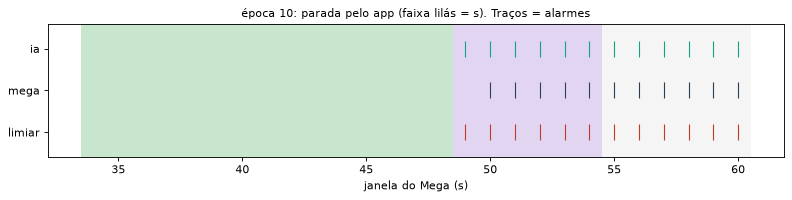

In [8]:
EP_S = next((e for e in dados["epocas"] if any(l["rotulo"] == "s" for l in linhas if l["epoca"] == e)), None)
if EP_S is None:
    print("esta sessão não tem s: sem gráfico de parada pelo app")
else:
    fig, ax = plt.subplots(figsize=(10, 2.6))
    ep = [l for l in linhas if l["epoca"] == EP_S]
    x = [l["janela_mega"] for l in ep]
    faixas(ax, [l["rotulo"] for l in ep], x)
    for k, (chave, cor) in enumerate((("limiar", "#c0392b"), ("mega", "#2c3e50"), ("ia", "#16a085"))):
        ys = [k if (l[chave] if chave != "ia" else bool(l["ia"] and l["ia"]["disparou"])) else np.nan for l in ep]
        ax.plot(x, ys, "|", ms=14, color=cor)
    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["limiar", "mega", "ia"]); ax.set_ylim(-0.6, 2.6)
    ax.set_xlabel("janela do Mega (s)"); ax.set_title("época %d: parada pelo app (faixa lilás = s). Traços = alarmes" % EP_S, fontsize=10)
    fig.tight_layout(); plt.show()

## 6 · Limites e honestidade

In [9]:
itens = []
if SIMULADO:
    itens.append(f"- **Simulado = teste de fumaça.** Os dados vêm de um modelo de brinquedo com semente fixa; as falhas são injetadas por regra. A ia acertar {EVENTOS_IA} aqui diz que o código segue a régua, não que a régua pega falha real.")
    itens.append("- **Uma pessoa, um motor, uma sessão.** Sem repetição, sem outro motor, sem outra pessoa marcando. O rótulo humano tem atraso e erro (no simulado esse atraso é zero).")
else:
    itens.append(f"- **Dado real, mas pequeno.** A ia acertou {EVENTOS_IA} episódios nesta gravação. Uma pessoa, um motor: o resultado descreve esta sessão, não a régua em geral. O rótulo humano tem atraso e erro.")
itens.append(f"- **O baseline é por época** e usa as janelas `n` (ou sem marcação) depois da calibração, até o primeiro rótulo de falha. Com menos de {avaliar.BASELINE_MIN} janelas a época fica `baseline_insuficiente` e a ia *não avaliou* (nunca *não detectou*).")
itens.append("- **Depois do disparo o motor está parado pelo relé B:** o que a ia vê ali não é falha nova, e por isso essas janelas ficam fora da conta.")
if SEG_S:
    itens.append(f"- **A parada comandada (`s`) é fora de distribuição:** a ia vai marcá-la ({SEG_S['ia_alarmes']}/{SEG_S['ia_avaliadas']} janelas). Quem a reclassifica é o rótulo (contexto), não o modelo. Por isso `alarmes_em_s` é *reportado*, não exigido zero, e o que exigimos zero é `anomalia`/`inconsistência` na `classe_final` das janelas `s`.")
if SEG_R and SIMULADO:
    itens.append("- **O ruído da sala (`r`)** no simulado é só um acréscimo no som; a IA o lê como inconsistência (o som sobe sem rpm/vib), e esse é o falso alarme dela. Na bancada real isso precisa de dados reais para calibrar.")
if SIMULADO:
    itens.append("- **Falsos alarmes:** o teto 0 em sessão nula é checado nos testes (com `--baseline-max`, para sobrar janelas fora da amostra), também só em simulado.")
display(Markdown("\n".join(itens)))

- **Simulado = teste de fumaça.** Os dados vêm de um modelo de brinquedo com semente fixa; as falhas são injetadas por regra. A ia acertar 9/9 aqui diz que o código segue a régua, não que a régua pega falha real.
- **Uma pessoa, um motor, uma sessão.** Sem repetição, sem outro motor, sem outra pessoa marcando. O rótulo humano tem atraso e erro (no simulado esse atraso é zero).
- **O baseline é por época** e usa as janelas `n` (ou sem marcação) depois da calibração, até o primeiro rótulo de falha. Com menos de 15 janelas a época fica `baseline_insuficiente` e a ia *não avaliou* (nunca *não detectou*).
- **Depois do disparo o motor está parado pelo relé B:** o que a ia vê ali não é falha nova, e por isso essas janelas ficam fora da conta.
- **A parada comandada (`s`) é fora de distribuição:** a ia vai marcá-la (2/2 janelas). Quem a reclassifica é o rótulo (contexto), não o modelo. Por isso `alarmes_em_s` é *reportado*, não exigido zero, e o que exigimos zero é `anomalia`/`inconsistência` na `classe_final` das janelas `s`.
- **O ruído da sala (`r`)** no simulado é só um acréscimo no som; a IA o lê como inconsistência (o som sobe sem rpm/vib), e esse é o falso alarme dela. Na bancada real isso precisa de dados reais para calibrar.
- **Falsos alarmes:** o teto 0 em sessão nula é checado nos testes (com `--baseline-max`, para sobrar janelas fora da amostra), também só em simulado.

## Extra (Tier 2): Isolation Forest

Fica para depois da aula, se sobrar tempo: ajustar um Isolation Forest (scikit-learn) nas mesmas janelas normais do baseline e comparar com a faixa **ia**. Não faz parte do Tier 0, por isso aqui não há código.